# Fitting the NEOARM model to a recording

This notebook fits the column of notebook 1 to a recording of `record_lens_changes.py`. The fit
starts from the numbers of notebook 1, as it will at the real NEOARM. Then the fitted model
predicts settings that the fit never saw.

**The recording.** `recordings/lens_changes_simulated_corrector_off_2026-11-22.csv` comes from
the simulated NEOARM. That microscope hides its own numbers. Its projector lenses sit in other
places with other coils. CL1, CL3 and the projector lenses have other gaps and bores, and their
centres are off the axis. Its objective sits at another distance, with another focal length
and another focus per OLf unit. Its deflectors have their own strengths and directions, CLA1
sits lower, and
its SightX is off the axis and turned. CM has another gap, which this fit holds fixed. Its source
has a size, which the model leaves out. Some of its parts also have another form than the model's.
Its lenses lag behind their DAC values (hysteresis), and the objective's post-field is shorter
than its pre-field. Its corrector is off, as on the NEOARM (Q13); the model does not know whether
the corrector is off, turns the beam over (a magnification of -1), or images it upright. Its
beam shift and tilt drive two pairs of coils each, and its console's pivot points are nearly
right, as after a recent alignment. So this is a test of a model whose
form is close to the microscope's, not equal. This notebook does not read the hidden numbers. Each
line of the table is one SightX frame. It holds the console's DAC values and the beam's centre and
rms radius in pixels.

The recording brings every lens to its value from below at each row, and at a few rows also from
above, one lens at a time. The model fits one lag per lens: from below a lens acts as if its DAC
value were lower by its lag, from above as if it were higher. The jump between the two approaches
pins the lag. Without it, the lag trades against the lens's strength, and the fit finds false
minima (stage 6b, 2026-11-21).

**The model.** The column is the list of TemGym components of notebook 1. The fit changes every
number except a few that hold the column's gauge freedoms, changes of the numbers that no
recording can see. The objective is fitted by how far the specimen sits beyond its focal plane,
and by how its focus follows OLf. Its focal length itself is held at notebook 1's value: the
recording sees it only weakly, and the predictions do not depend on it (example E9). So the
objective's focal length is not known from this recording. CM and the corrector are static
components, set by no console value (requirement M2), but their positions and strengths are
numbers like the others. The fitted numbers need not be the microscope's. The predictions must
be right.

**The test.** Some settings stay out of the fit. They are three MAG rows, two DIFF rows, the
settings with several lenses moved at once, spot 0, the focus series of two rows and the
from-above settings at 1.5 m. The fitted model predicts them once, at the end.

In [1]:
import csv
import json
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from jax.flatten_util import ravel_pytree

import temgym_core.components.lenses
from temgym_core.components import ABCDTransfer, Deflector, Lens, Plane, PolePieceLens
from temgym_core.components.specimens import AU_RINGS
from temgym_core.constants import energy2wavelength
from temgym_core.ray import Ray
from temgym_core.run import position_and_angle_response, run_to_end

jax.config.update("jax_enable_x64", True)
# A pole-piece lens integrates the ray across its field in POLE_PIECE_STEPS steps, 200 by default.
# 100 steps move the beam centres of this recording by 0.005 px at most and the sizes by 0.03 %,
# against 200, and halve the time of the fit (requirement R33).
temgym_core.components.lenses.POLE_PIECE_STEPS = 100

HERE = Path.cwd()
(HERE / "figures").mkdir(exist_ok=True)
VOLTAGE = 200e3
# The SightX is 12 cm wide, with 1916 pixels. The recording reads the frames at binning 4.
PIXEL_M = 0.12 / 1916 * 4
FRAME_HALF_WIDTH_PX = 479 / 2
console = json.loads(
    (HERE.parent / "microscope_inversion/recordings/2026-11-17/console_tables.json").read_text()
)
projector = json.loads((HERE / "projector_lenses.json").read_text())
condenser = json.loads((HERE / "condenser.json").read_text())
drawing = json.loads((HERE.parent / "virtual_neoarm/neoarm_column_diagram.json").read_text())["z_m"]
L = drawing["Screen"]
z_drawing = {name: z / L for name, z in drawing.items()}
MM = 1e-3 / L
PROJECTOR = ("IL1", "IL2", "IL3", "PL1")
DEFLECTORS = ("SpotA", "CLA1", "CLA2", "PLA")
# The positions of SpotA, CLA1 and CLA2 are the choices of notebook 1. The projector deflector PLA
# starts midway between IL3 and PL1. No drawing gives its place.
DEFLECTOR_Z = {
    "SpotA": -0.66,
    "CLA1": -0.5786,
    "CLA2": -0.5623,
    "PLA": 0.5 * (projector["lens_z"]["IL3"] + projector["lens_z"]["PL1"]),
}

## The recording

A lens under free lens control has the free lens control value. Otherwise it has the console's
value. The objective's fine focus OLf counts from its value in the MAG 40k row, the standard
focus. A kicked frame has the kick on top of the deflector value of its line. The deflector values
count from the aligned state of notebook 1. For CLA1 and CLA2 it is the MAG 40k row. For SpotA it
is spot 2 at alpha 1. A frame where the script found no beam has no centre, and it stays out.

The fit uses the beam size of MAG frames only. Every DIFF frame reaches the top count of the
camera, so its size is not a measurement. A MAG beam smaller than 15 px rms may also reach it.

In [2]:
mag_40k = next(r for r in console["rows"]["MAG"] if r["mag"][2] == "X40k")
spot_2 = next(r for r in console["spot_alpha"] if r["spot"] == 2 and r["alpha"] == 1)
aligned = {
    "SpotA": spot_2["SpotA"],
    "CLA1": mag_40k["CLA1"],
    "CLA2": mag_40k["CLA2"],
    "PLA": mag_40k["PLA"],
}

RECORDING = HERE / "recordings/lens_changes_simulated_corrector_off_2026-11-22.csv"
with open(RECORDING, newline="") as table:
    every_frame = list(csv.DictReader(table))
frames = [line for line in every_frame if line["beam_x_px"] != "nan"]
lost = [line["setting"] for line in every_frame if line["beam_x_px"] == "nan"]
print(f"{len(lost)} frames with no beam found, in the settings {sorted(set(lost))}")


def lens_value(line, name):
    """Return the DAC value that a lens had for one frame."""
    if line.get(f"{name}_flc_on") == "1":
        return float(line[f"{name}_flc_dac"])
    return float(line[name])


def deflector_value(line, name):
    """Return the DAC values (x, y) of a deflector for one frame, from its aligned state."""
    kick = (float(line["kick_x"]), float(line["kick_y"])) if line["deflector"] == name else (0, 0)
    return [
        float(line[f"{name}_{axis}"]) + kick[i] - aligned[name][i] for i, axis in enumerate("xy")
    ]


def approach(line, name):
    """Return -1 for a lens that came to its value from above in one frame, 1 for from below."""
    return -1.0 if name in line.get("from_above", "").split() else 1.0


# Each frame's row holds the DAC values of CL1, CL3, CM, the projector lenses and OLf (from its
# value at X40k), then the direction each of these came from.
lenses = np.array(
    [
        [lens_value(f, n) for n in ("CL1", "CL3", "CM") + PROJECTOR]
        + [lens_value(f, "OLf") - mag_40k["OLf"]]
        + [approach(f, n) for n in ("CL1", "CL3", "CM") + PROJECTOR + ("OLf",)]
        for f in frames
    ]
)
deflectors = np.array([[deflector_value(f, n) for n in DEFLECTORS] for f in frames])
centre_px = np.array([[float(f["beam_x_px"]), float(f["beam_y_px"])] for f in frames])
rms_px = np.array([float(f["beam_rms_px"]) for f in frames])
has_size = np.array([f["function_mode"] == "0" for f in frames]) & (rms_px >= 15)
setting = np.array([f["setting"] for f in frames])

KEPT_BACK_ROWS = ("MAG row 7", "MAG row 15", "MAG row 22", "DIFF row 2", "DIFF row 12")
assert not any(name in KEPT_BACK_ROWS for name in lost), "a kept-back row lost its beam"
# A setting with several lenses moved at once names two or three lenses after the row.
combined = np.array([name.count(",") >= 2 for name in setting])
spot_0 = setting == "MAG row 13, spot 0"
# The from-above settings at 1.5 m stay out, so the lags must carry over from the other rows.
above_kept = np.array(
    [name.startswith("DIFF row 13, ") and "from above" in name for name in setting]
)
# The whole focus series at MAG 100k and at 1 m stays out, so the focus law must carry over from
# the other rows.
KEPT_BACK_FOCUS_ROWS = ("MAG row 17", "DIFF row 11")
focus_kept = np.array(
    [name.split(", ")[0] in KEPT_BACK_FOCUS_ROWS and ", OLf " in name for name in setting]
)
kept_back = np.isin(setting, KEPT_BACK_ROWS) | combined | spot_0 | focus_kept | above_kept
print(
    f"{len(frames)} frames: {np.sum(~kept_back)} to fit, {np.sum(kept_back)} kept back, "
    f"{np.sum(has_size)} with a beam size"
)
print("kept-back settings:", sorted(set(setting[kept_back])))

44 frames with no beam found, in the settings ['MAG row 13, OLf +1000', 'MAG row 13, OLf +3000', 'MAG row 13, OLf -3000', 'MAG row 17, OLf +3000', 'MAG row 17, OLf -3000']
1613 frames: 1397 to fit, 216 kept back, 564 with a beam size
kept-back settings: [np.str_('DIFF row 11, OLf +1000'), np.str_('DIFF row 11, OLf +3000'), np.str_('DIFF row 11, OLf -1000'), np.str_('DIFF row 11, OLf -3000'), np.str_('DIFF row 12'), np.str_('DIFF row 13, CL1 from above'), np.str_('DIFF row 13, CL3 from above'), np.str_('DIFF row 13, IL1 from above'), np.str_('DIFF row 13, IL2 from above'), np.str_('DIFF row 13, IL3 from above'), np.str_('DIFF row 13, PL1 from above'), np.str_('DIFF row 2'), np.str_('DIFF row 7, IL1 +1000, IL3 -1000'), np.str_('DIFF row 7, IL2 -1000, IL3 +1000, PL1 -1000'), np.str_('MAG row 13, IL1 +1000, IL3 -1000'), np.str_('MAG row 13, IL2 -1000, IL3 +1000, PL1 -1000'), np.str_('MAG row 13, spot 0'), np.str_('MAG row 15'), np.str_('MAG row 17, OLf +1000'), np.str_('MAG row 17, OLf -10

## The model

`column` is the list of components of notebook 1, with the fitted numbers in place. The fitted
numbers are in one dictionary:

- `z` and `turns` are the position (L) and the ampere-turns per DAC unit of IL1, IL2, IL3, PL1.
- `gap` and `bore` are the logarithms of the pole-piece gap and bore radius (L) of CL1, CL3 and
  the projector lenses.
- `centre` is the centre (x, y) of each of these six lenses, in micrometres.
- `kick` is the kick (x, y) of each deflector for a change of (x, y), in 1e-7 rad per DAC unit.
- `offset` is the kick of each deflector at its aligned state, in 1e-4 rad. An operator aligns
  the real column, so the aligned state need not be a state with no kick.
- `spread` is the logarithm of the rms spread of angles at the source (metres per L).
- `objective_gap` is the logarithm of how far the specimen sits beyond the objective's focal
  plane (L). The objective's fields before and after the specimen sit at its focal length plus
  this gap from the specimen.
- `focus` is the change of the objective's excitation per DAC unit of OLf, in 1e-7. The strength
  of a magnetic lens goes as the square of its excitation, so its focal length goes as the
  inverse square.
- `cl3_z`, `cm_z` and `deflector_z` are the positions (L) of CL3, CM, SpotA, CLA1, CLA2 and PLA.
- `condenser_turns` is the ampere-turns per DAC unit of CL1, CL3 and CM, each its own. The
  console's spot table, matched in the simulated NEOARM, needs CM much weaker than CL1 and CL3.
- `lag` is how far each lens's field lags behind its DAC value, in DAC units, for CL1, CL3 and the
  projector lenses. Each approach always comes from the same distance below or above, so the lag
  of each lens is the same at every setting from that side (requirement H3).
- `camera_shift` is where the axis of the column meets the SightX, in px from the middle.

The camera can also show a mirror image. The fit tries both, and keeps the better one.

Some changes of the numbers change nothing that a recording can see. They are gauge freedoms:

- Turning the whole column about its axis, with the camera, changes nothing.
- Moving CL1 to CLA2 together along the axis changes nothing below the corrector, when the
  corrector images them one to one.
- Moving the corrector along the axis with a change of its length trades against the other
  positions.
- CM's gap trades against its bore, and both trade against CM's strength. CM's DAC value never
  changes in a recording, so only its focusing at that value counts.

The objective's focal length is held too. The objective sits only 0.03 mm further from the
specimen than its focal length, about 2 mm. Where the objective's image lands depends on that
small gap, so the recording sees the gap well. The focal length and the distance can change
together, with the gap kept, and the recording barely sees the difference: in a test of
2026-11-22, held at 0.82 to 1.22 times notebook 1's value, the refitted misfit ran from 116 to
215 (the best fit here: 139) and no kept-back prediction moved by more than 0.41 px. Fitted as
well, the focal length slid to wrong values. It is not a gauge freedom, since the misfit changes
a little, but the recording cannot tell its value, and the predictions do not need it.

Two more numbers are held: CM's bore and the corrector's bottom. The recording sees them, but
only at about 3e-8 of its strongest change, as weakly as the weakest change of the fitted
numbers. Fitted, they let the first steps of the fit wander into other valleys: on 2026-11-21 the
best misfit was then 3673 against 112 with them held. The checks near the end show that their
values do not move a prediction.

Each freedom needs one number held at a chosen value. Any choice gives the same predictions.
These numbers are in a second dictionary, the fit does not change them, and the notebook checks
near the end that their choice does not move the predictions. They are the camera's turn against
the column (rad), CL1's position (L), the logarithms of CM's gap and bore (L) and the positions
of the corrector's top and bottom (L), and the logarithm of the objective's focal length (L).
Every other number is fitted.

In [3]:
FIXED = dict(
    camera_turn=jnp.zeros(()),
    cl1_z=jnp.asarray(z_drawing["CL1"]),
    cm_gap=jnp.log(condenser["pole_gap"]["CM"]),
    cm_bore=jnp.log(condenser["bore_radius"]["CM"]),
    corrector_z=jnp.array([z_drawing["Corrector Top"], z_drawing["Corrector Bottom"]]),
    objective_f=jnp.log(projector["objective_f"]),
)


def column(numbers, fixed, corrector_on, lens_dac, deflector_dac):
    """Return the column from the source to the SightX for one frame's DAC values.

    ``lens_dac`` is one row of ``lenses``: eight DAC values (CL1, CL3, CM, IL1, IL2, IL3, PL1, OLf),
    then the direction each came from, 1 from below and -1 from above. ``corrector_on`` is 1 for a
    corrector that images with a magnification of -1, 0 for one that is off (free space).
    """
    gap, bore, centre = jnp.exp(numbers["gap"]), jnp.exp(numbers["bore"]), numbers["centre"] * 1e-6
    # The lenses act as if their DAC values were lower by their lag from below, higher from above.
    lens_dac, direction = lens_dac[:8], lens_dac[8:]
    lag = jnp.concatenate([numbers["lag"][:2], jnp.zeros(1), numbers["lag"][2:], jnp.zeros(1)])
    lens_dac = lens_dac - direction * lag
    excitation = 1 + numbers["focus"] * 1e-7 * lens_dac[7]
    objective_f = jnp.exp(fixed["objective_f"]) / excitation**2
    objective_z = jnp.exp(fixed["objective_f"]) + jnp.exp(numbers["objective_gap"])
    condenser_turns = numbers["condenser_turns"]
    # The corrector is a transfer from its top to its bottom (requirement M2). On, it images with a
    # magnification of -1. Off, it is free space.
    corrector_length = fixed["corrector_z"][1] - fixed["corrector_z"][0]
    sign = 1 - 2 * corrector_on
    corrector = ABCDTransfer(
        A=sign * jnp.eye(2),
        B=(1 - corrector_on) * corrector_length * jnp.eye(2),
        D=sign * jnp.eye(2),
        z=fixed["corrector_z"][0],
        length=corrector_length,
    )
    kick = [
        numbers["kick"][i] * 1e-7 * L @ deflector_dac[i] + numbers["offset"][i] * 1e-4 * L
        for i in range(4)
    ]
    spot_a = Deflector(z=numbers["deflector_z"][0], def_x=kick[0][0], def_y=kick[0][1])
    # CLA1 and CLA2 drive the same two pairs of coils, at the drawing's CLA1 and CLA2. Each shares
    # its kick between them so that the kick acts at its pivot plane, deflector_z, which may lie
    # beyond the coils (a share below 0 or above 1): s from the upper pair, 1 - s from the lower.
    upper, lower = DEFLECTOR_Z["CLA1"], DEFLECTOR_Z["CLA2"]
    share = [(lower - numbers["deflector_z"][i]) / (lower - upper) for i in (1, 2)]
    upper_kick = share[0] * kick[1] + share[1] * kick[2]
    lower_kick = (1 - share[0]) * kick[1] + (1 - share[1]) * kick[2]
    upper_coils = Deflector(z=upper, def_x=upper_kick[0], def_y=upper_kick[1])
    lower_coils = Deflector(z=lower, def_x=lower_kick[0], def_y=lower_kick[1])
    pla = Deflector(z=numbers["deflector_z"][3], def_x=kick[3][0], def_y=kick[3][1])
    cl1 = PolePieceLens(
        z=fixed["cl1_z"],
        turns=condenser_turns[0],
        current=lens_dac[0],
        gap=gap[0],
        bore_radius=bore[0],
        x0=centre[0, 0],
        y0=centre[0, 1],
    )
    # On the drawing, CL3 sits where the label says CL2.
    cl3 = PolePieceLens(
        z=numbers["cl3_z"],
        turns=condenser_turns[1],
        current=lens_dac[1],
        gap=gap[1],
        bore_radius=bore[1],
        x0=centre[1, 0],
        y0=centre[1, 1],
    )
    cm = PolePieceLens(
        z=numbers["cm_z"],
        turns=condenser_turns[2],
        current=lens_dac[2],
        gap=jnp.exp(fixed["cm_gap"]),
        bore_radius=jnp.exp(fixed["cm_bore"]),
    )
    projector_lenses = [
        PolePieceLens(
            z=numbers["z"][i],
            turns=numbers["turns"][i],
            current=lens_dac[3 + i],
            gap=gap[2 + i],
            bore_radius=bore[2 + i],
            x0=centre[2 + i, 0],
            y0=centre[2 + i, 1],
        )
        for i in range(4)
    ]
    return [
        cl1,
        spot_a,
        cl3,
        upper_coils,
        lower_coils,
        corrector,
        cm,
        Lens(z=-objective_z, focal_length=objective_f),
        Lens(z=objective_z, focal_length=objective_f),
        *projector_lenses[:3],
        pla,
        projector_lenses[3],
        Plane(z=1.0),
    ]

Three rays leave the middle of the source. The first is the centre of the beam. The second and the
third leave at one rms spread of angles, along x and along y. Where they land gives the centre and
the rms radius of the beam on the SightX.

The recording measures the radius from the pixels above a fifth of the brightest pixel. For a
Gaussian beam, that radius is a fixed fraction of the true rms radius. With a = ln 5, the fraction
is sqrt((1 - (1 + a) e^-a) / (1 - e^-a)) = 0.773. The model multiplies by it.

In [4]:
cut = np.log(5.0)
MEASURED_FRACTION = np.sqrt((1 - (1 + cut) * np.exp(-cut)) / (1 - np.exp(-cut)))


def beam_on_sightx(numbers, fixed, corrector_on, lens_dac, deflector_dac, mirror):
    """Return the beam's centre (x, y) and its measured rms radius on the SightX, in pixels."""
    spread = jnp.exp(numbers["spread"])
    rays = Ray(
        x=jnp.zeros(3),
        y=jnp.zeros(3),
        dx=jnp.array([0.0, spread, 0.0]),
        dy=jnp.array([0.0, 0.0, spread]),
        z=jnp.full(3, z_drawing["Source"]),
        pathlength=jnp.zeros(3),
        voltage=jnp.full(3, VOLTAGE),
    )
    out = run_to_end(rays, column(numbers, fixed, corrector_on, lens_dac, deflector_dac))
    x, y = out.x / PIXEL_M, mirror * out.y / PIXEL_M
    cos, sin = jnp.cos(fixed["camera_turn"]), jnp.sin(fixed["camera_turn"])
    xy = jnp.stack([cos * x - sin * y, sin * x + cos * y]) + numbers["camera_shift"][:, None]
    radius = jnp.sqrt(jnp.sum((xy[:, 1:] - xy[:, :1]) ** 2) / 2) * MEASURED_FRACTION
    return xy[:, 0], radius


beams = jax.vmap(beam_on_sightx, in_axes=(None, None, None, 0, 0, None))

## The start

The start is notebook 1. The deflector strength of notebook 1, 3e-7 rad per DAC unit, is a guess.
The lenses start on the axis.

In [5]:
start = dict(
    z=jnp.array([projector["lens_z"][n] for n in PROJECTOR]),
    turns=jnp.array([projector["ampere_turns_per_dac"][n] for n in PROJECTOR]),
    gap=jnp.log(
        jnp.array(
            [condenser["pole_gap"]["CL1"], condenser["pole_gap"]["CL3"]]
            + [projector["pole_gap"][n] for n in PROJECTOR]
        )
    ),
    bore=jnp.log(
        jnp.array(
            [condenser["bore_radius"]["CL1"], condenser["bore_radius"]["CL3"]]
            + [projector["bore_radius"][n] for n in PROJECTOR]
        )
    ),
    centre=jnp.zeros((6, 2)),
    # PLA's start is a guess of its strength, about 1 urad per unit. No source gives it.
    kick=jnp.stack([3.0 * jnp.eye(2)] * 3 + [10.0 * jnp.eye(2)]),
    offset=jnp.zeros((4, 2)),
    spread=jnp.log(condenser["source_spread"]),
    objective_gap=jnp.log(projector["objective_z"] - projector["objective_f"]),
    # A guess: about 1 nm of focus per DAC unit.
    focus=jnp.asarray(2.5),
    camera_shift=jnp.zeros(2),
    cl3_z=jnp.asarray(z_drawing["CL2"]),
    cm_z=jnp.asarray(z_drawing["CLMini"]),
    deflector_z=jnp.array([DEFLECTOR_Z[name] for name in DEFLECTORS]),
    condenser_turns=jnp.full(3, condenser["ampere_turns_per_dac"]),
    lag=jnp.zeros(6),
)
u_start, numbers_from = ravel_pytree(start)
print(f"{u_start.size} fitted numbers")

76 fitted numbers


## The misfit

The misfit has three parts, each in units of its allowed error.

1. The beam centre of each frame, to 1 px. This is about the scatter of the centre on the SightX.
2. The beam size of each MAG frame with a size, to 3 %, as (model - measured) / measured. A beam
   has the same size a little before and a little past the condenser's focus. A logarithm of the
   sizes would cost without bound at the focus, where the model's beam has no size, so a fit that
   started a frame on the wrong side of the focus could never cross to the other (2026-11-22:
   about 190 frames on the wrong side, misfit 18 938 against 145 in a test). The difference
   costs little there.
3. The console's labels, as in notebook 1 (requirement M11). The mean magnification of MAG 8k to
   500k agrees with the labels to 2 %. The mean camera length of DIFF 8 cm to 2 m does too.
   The frames alone cannot separate the deflector strength from the magnification.

Priors keep each number near notebook 1, with a wide allowed error. Each allowed error is a
choice. The objective's gap may move by a factor of 3: the recording sees it well.

In [6]:
CENTRE_ERROR_PX = 1.0
# In the list of `column`, the objective's field after the specimen is the ninth component. From it
# on, the list is the column after the specimen, as in notebook 1.
FIRST_AFTER_SPECIMEN = 8
SIZE_ERROR = 0.03
LABEL_ERROR = 0.02
# The label term leaves out the kept-back rows, so that the fit uses nothing of them.
KEPT_BACK_SELECTORS = {"MAG": (7, 15, 22), "DIFF": (2, 12)}
mag_rows = [
    r
    for i, r in enumerate(console["rows"]["MAG"])
    if 8000 <= r["mag"][0] <= 500000
    and r["mag"][2] != "X25k"
    and i not in KEPT_BACK_SELECTORS["MAG"]
]
diff_rows = [
    r
    for i, r in enumerate(console["rows"]["DIFF"])
    if r["mag"][1] == "mm"
    and r["OLf"] > 0
    and 80 <= r["mag"][0] <= 2000
    and i not in KEPT_BACK_SELECTORS["DIFF"]
]
mag_label = np.array([r["mag"][0] for r in mag_rows], float)
diff_label = np.array([r["mag"][0] / 1000 / L for r in diff_rows], float)


def label_scale(numbers, fixed, rows):
    """Return the magnification and the camera length (L) after the specimen for console rows."""

    def response(dac):
        # The column before the specimen does not matter here, so the corrector's state does not.
        parts = column(
            numbers,
            fixed,
            1.0,
            # The console's rows, with every lens from below.
            jnp.concatenate([jnp.zeros(3), dac, jnp.zeros(1), jnp.ones(8)]),
            jnp.zeros((len(DEFLECTORS), 2)),
        )
        after_specimen = [Plane(z=0.0)] + parts[FIRST_AFTER_SPECIMEN:]
        return position_and_angle_response(after_specimen, voltage=VOLTAGE)

    return jax.vmap(response)(jnp.array([[r[n] for n in PROJECTOR] for r in rows], float))


def misfits(u, mirror, lenses, deflectors, centre_px, rms_px, has_size, fixed, corrector_on):
    """Return every misfit of the fitted numbers ``u``, each in units of its allowed error."""
    numbers = numbers_from(u)
    centre, radius = beams(numbers, fixed, corrector_on, lenses, deflectors, mirror)
    magnification, _ = label_scale(numbers, fixed, mag_rows)
    _, camera_length = label_scale(numbers, fixed, diff_rows)
    return jnp.concatenate(
        [
            ((centre - centre_px) / CENTRE_ERROR_PX).ravel(),
            jnp.where(has_size, radius / rms_px - 1, 0.0) / SIZE_ERROR,
            jnp.mean(jnp.log(jnp.abs(magnification) / mag_label))[None] / LABEL_ERROR,
            jnp.mean(jnp.log(jnp.abs(camera_length) / diff_label))[None] / LABEL_ERROR,
            (numbers["z"] - start["z"]) / (10 * MM),
            jnp.log(numbers["turns"] / start["turns"]) / 0.03,
            (numbers["gap"] - start["gap"]) / np.log(1.5),
            (numbers["bore"] - start["bore"]) / np.log(1.5),
            numbers["centre"].ravel() / 200.0,
            numbers["offset"].ravel() / 1e3,
            (numbers["objective_gap"] - start["objective_gap"])[None] / np.log(3),
            (numbers["cl3_z"] - start["cl3_z"])[None] / (10 * MM),
            (numbers["cm_z"] - start["cm_z"])[None] / (10 * MM),
            # The pivot planes of CLA1 and CLA2 are set by the balances, and with the pivots on the
            # specimen they lie about 85 mm below the coils in the simulated NEOARM (2026-11-22).
            (numbers["deflector_z"] - start["deflector_z"]) / (jnp.array([10, 200, 200, 10]) * MM),
            # CM is a mini lens. Its strength may differ from the drawing's far more than the
            # strengths of CL1 and CL3. The allowed errors are choices.
            jnp.log(numbers["condenser_turns"] / start["condenser_turns"])
            / jnp.array([0.2, 0.2, 0.6]),
            # A lag as large as the approach would mean the approach does not wipe the lens's
            # memory, so the approach of 2000 DAC units is the lag's scale, not a bound.
            numbers["lag"] / 2000.0,
            (numbers["focus"] - start["focus"])[None] / 10.0,
        ]
    )

## The fit

Levenberg-Marquardt steps in JAX, as in `fit_projector_lenses.py`. JAX gives the derivatives
through TemGym.

The misfit lies in a long, curved valley: its derivatives differ by a factor of about 1e9 between
the best and the worst determined changes. A plain step follows the valley only in tiny steps,
and on 2026-11-21 it stopped 3.5 px of prediction short of the minimum. So each step also takes
the bend of the valley into account (geodesic acceleration, Transtrum and Sethna 2012): the second
derivative of the misfits along the step, which JAX gives at about the cost of two misfits. A step
whose bend is more than 0.75 of the step itself is refused.

The fit starts the objective's gap at notebook 1's 0.03 mm, and also at several times it, to
check that the start does not matter. It starts CM's strength at the drawing's and at two
smaller fractions of it. Each start runs with both mirror choices, and with the
corrector on and off (requirement M2). Each also runs with the deflectors' kicks reversed: a
corrector that images with +1 instead of -1 is the same column with everything above it turned
by half a turn, and the fit finds that column only from a start whose kicks point the other way
(a test with a +1 corrector, 2026-11-22: misfit 22 534 from the usual starts). The kicks'
direction is not known at the real NEOARM either. On a GPU all the fits run at once.

A fit stops when its misfit falls by less than 0.1 % over 50 steps (requirement R34). A fit that
reaches 1000 steps first says so.

This cell and the refits of example E9 below are slow. The whole notebook took about 16 minutes on
the GPU of 2026-11-22, most of it here. On a CPU it takes hours.

In [7]:
@jax.jit
def fit(
    u, mirror, lenses, deflectors, centre_px, rms_px, has_size, fixed, corrector_on, most_steps
):
    """Run Levenberg-Marquardt steps from ``u`` until the misfit stops falling.

    The fit stops when the misfit falls by less than STOP_FRACTION over STOP_STEPS steps, or after
    ``most_steps``. Return the end, its misfit and the number of steps.
    """

    def residuals(v):
        return misfits(
            v, mirror, lenses, deflectors, centre_px, rms_px, has_size, fixed, corrector_on
        )

    def cost_of(v):
        r = residuals(v)
        return r @ r

    def step(state):
        u, damping, cost = state
        r = residuals(u)
        jacobian = jax.jacfwd(residuals)(u)
        h = jacobian.T @ jacobian
        damped = h + damping * jnp.diag(jnp.diag(h) + 1e-9)
        velocity = jnp.linalg.solve(damped, -jacobian.T @ r)
        # The second derivative of the misfits along the step.
        bend = jax.jvp(lambda w: jax.jvp(residuals, (w,), (velocity,))[1], (u,), (velocity,))[1]
        acceleration = jnp.linalg.solve(damped, -jacobian.T @ bend)
        trial = u + velocity + acceleration / 2
        trial_cost = cost_of(trial)
        small_bend = 2 * jnp.linalg.norm(acceleration) <= 0.75 * jnp.linalg.norm(velocity)
        better = jnp.isfinite(trial_cost) & (trial_cost < cost) & small_bend
        return (
            jnp.where(better, trial, u),
            jnp.where(better, damping / 3, damping * 2),
            jnp.where(better, trial_cost, cost),
        )

    def stretch(state):
        """Run STOP_STEPS steps, and keep the misfit from before them."""
        u, damping, cost, _, steps = state
        u, damping, new_cost = jax.lax.fori_loop(
            0, STOP_STEPS, lambda _, s: step(s), (u, damping, cost)
        )
        return u, damping, new_cost, cost, steps + STOP_STEPS

    def falling(state):
        _, _, cost, cost_before, steps = state
        return (cost < (1 - STOP_FRACTION) * cost_before) & (steps < most_steps)

    cost = cost_of(u)
    u, _, cost, _, steps = jax.lax.while_loop(
        falling, stretch, stretch((u, 1e-2, cost, jnp.inf, 0))
    )
    return u, cost, steps


fit_data = tuple(
    jnp.asarray(x[~kept_back]) for x in (lenses, deflectors, centre_px, rms_px, has_size)
)
GAP_FACTORS = (1.0, 2.0, 3.0)
# CM's strength starts at these fractions of the drawing's. The console's spot table needs CM much
# weaker than the drawing's (the simulated NEOARM, matched to it: 0.38). The fractions are choices.
CM_FACTORS = (1.0, 0.5, 0.3)
STOP_STEPS = 50
STOP_FRACTION = 1e-3
MOST_STEPS = 1000
starts = [
    (mirror, factor, on, kick_sign)
    for on in (1.0, 0.0)
    for kick_sign in (1.0, -1.0)
    for mirror in (1.0, -1.0)
    for factor in [(gap, cm) for gap in GAP_FACTORS for cm in CM_FACTORS]
]
start_mirror = jnp.array([mirror for mirror, _, _, _ in starts])
start_on = jnp.array([on for _, _, on, _ in starts])
u_starts = jnp.stack(
    [
        ravel_pytree(
            dict(
                start,
                objective_gap=start["objective_gap"] + np.log(factor[0]),
                condenser_turns=start["condenser_turns"] * jnp.array([1.0, 1.0, factor[1]]),
                # The corrector's sign turns the deflectors above it. PLA lies below it.
                kick=start["kick"].at[:3].multiply(kick_sign),
            )
        )[0]
        for _, factor, _, kick_sign in starts
    ]
)
# Every start runs at once on the GPU, for at most FIRST_STEPS steps. Then, for each state of the
# corrector, the starts with the better mirror choice go on. The other mirror choice is lost by
# then, and it would only make the rest wait.
FIRST_STEPS = 300
fit_starts = jax.jit(jax.vmap(fit, in_axes=(0, 0) + (None,) * 6 + (0, None)))
u_ends, held_cost, held_steps = fit_starts(
    u_starts, start_mirror, *fit_data, FIXED, start_on, FIRST_STEPS
)
# For each state of the corrector and direction of the kicks, the starts with the mirror choice
# of its best start go on.
best_mirror = {}
for on in (1.0, 0.0):
    for kick_sign in (1.0, -1.0):
        group = [k for k, (_, _, o, s) in enumerate(starts) if o == on and s == kick_sign]
        best_mirror[on, kick_sign] = float(
            start_mirror[group[int(jnp.argmin(held_cost[jnp.array(group)]))]]
        )
going_on = np.flatnonzero(
    [mirror == best_mirror[on, kick_sign] for mirror, _, on, kick_sign in starts]
)
u_free, cost_free, steps_free = fit_starts(
    u_ends[going_on], start_mirror[going_on], *fit_data, FIXED, start_on[going_on], MOST_STEPS
)
u_ends = u_ends.at[going_on].set(u_free)
cost = held_cost.at[going_on].set(cost_free)
steps = held_steps.at[going_on].add(steps_free)
# A start that went on and used all MOST_STEPS steps says so (requirement R34, example E17). A
# start with the other mirror choice was left after FIRST_STEPS steps. Most starts end far above
# the best misfit: they are where the fit got lost, and the check of the starts below leaves them
# out.
at_limit = set(going_on[np.asarray(steps_free) >= MOST_STEPS].tolist())
for k, (mirror, factor, on, kick_sign) in enumerate(starts):
    end = numbers_from(u_ends[k])
    if k not in going_on:
        how = f", left after {FIRST_STEPS} steps (the other mirror choice)"
    elif k in at_limit:
        how = ", reached its step limit"
    else:
        how = ", stopped on its misfit (R34)"
    print(
        f"corrector {'on ' if on else 'off'}, kicks {kick_sign:+.0f}, mirror {mirror:+.0f}, "
        f"gap and CM started at {factor[0]} and {factor[1]} "
        f"times notebook 1's: misfit {float(cost[k]):.0f} after {int(steps[k])} steps"
        + how
        + f"; gap {np.exp(float(end['objective_gap'])) / MM:.4f} mm"
    )
BEST = int(jnp.argmin(cost))
MIRROR = float(start_mirror[BEST])
CORRECTOR_ON = float(start_on[BEST])
print(f"best: corrector {'on' if CORRECTOR_ON else 'off'}, mirror {MIRROR:+.0f}")
not_finished = int(steps[BEST]) >= MOST_STEPS
print("the best fit reached its step limit" if not_finished else "the best fit finished (R34)")
assert not not_finished
u_fit = u_ends[BEST]
fitted = numbers_from(u_fit)

corrector on , kicks +1, mirror +1, gap and CM started at 1.0 and 1.0 times notebook 1's: misfit 287233 after 300 steps, left after 300 steps (the other mirror choice); gap 0.0291 mm
corrector on , kicks +1, mirror +1, gap and CM started at 1.0 and 0.5 times notebook 1's: misfit 508492 after 300 steps, left after 300 steps (the other mirror choice); gap 0.0310 mm
corrector on , kicks +1, mirror +1, gap and CM started at 1.0 and 0.3 times notebook 1's: misfit 434070 after 250 steps, left after 300 steps (the other mirror choice); gap 0.0327 mm
corrector on , kicks +1, mirror +1, gap and CM started at 2.0 and 1.0 times notebook 1's: misfit 349875 after 300 steps, left after 300 steps (the other mirror choice); gap 0.0543 mm
corrector on , kicks +1, mirror +1, gap and CM started at 2.0 and 0.5 times notebook 1's: misfit 472425 after 300 steps, left after 300 steps (the other mirror choice); gap 0.0554 mm
corrector on , kicks +1, mirror +1, gap and CM started at 2.0 and 0.3 times notebook 

best: corrector on, mirror -1
the best fit finished (R34)


## The fitted numbers

The numbers after the fit, against the start of notebook 1. The deflector strength and the
magnification can trade against each other. The labels fix their product only to their 2 %.

In [8]:
print(f"camera: mirror {MIRROR:+.0f}")
for name, key in (("CL3", "cl3_z"), ("CM", "cm_z")):
    print(f"{name}: z {float(fitted[key]) / MM:6.1f} mm (start {float(start[key]) / MM:6.1f})")
for i, name in enumerate(DEFLECTORS):
    print(
        f"{name}: z {float(fitted['deflector_z'][i]) / MM:6.1f} mm "
        f"(start {float(start['deflector_z'][i]) / MM:6.1f})"
    )
for name, turns, turns_start in zip(
    ("CL1", "CL3", "CM"), fitted["condenser_turns"], start["condenser_turns"]
):
    print(f"{name} coils: ampere-turns per DAC {float(turns):.4f} (start {float(turns_start):.4f})")
for name, lag in zip(("CL1", "CL3") + PROJECTOR, np.asarray(fitted["lag"])):
    print(f"{name}: lag {lag:6.1f} DAC units")
for i, name in enumerate(PROJECTOR):
    print(
        f"{name}: z {float(fitted['z'][i]) / MM:5.1f} mm (start {float(start['z'][i]) / MM:5.1f}), "
        f"ampere-turns per DAC {float(fitted['turns'][i]):+.4f} (start "
        f"{float(start['turns'][i]):+.4f})"
    )
for i, name in enumerate(("CL1", "CL3") + PROJECTOR):
    print(
        f"{name}: gap {np.exp(float(fitted['gap'][i])) / MM:5.2f} mm (start "
        f"{np.exp(float(start['gap'][i])) / MM:5.2f}), "
        f"bore {np.exp(float(fitted['bore'][i])) / MM:5.2f} mm (start "
        f"{np.exp(float(start['bore'][i])) / MM:5.2f}), "
        f"centre {np.round(np.asarray(fitted['centre'][i]), 1)} um"
    )
for i, name in enumerate(DEFLECTORS):
    print(
        f"{name}: kick per DAC unit (1e-7 rad) "
        f"{np.round(np.asarray(fitted['kick'][i]), 3).tolist()}, "
        f"offset {np.round(np.asarray(fitted['offset'][i]) * 1e-4 * 1e3, 3)} mrad"
    )
print(
    f"objective: focal length {np.exp(float(FIXED['objective_f'])) / MM:.3f} mm (held), "
    f"gap {np.exp(float(fitted['objective_gap'])) / MM:.4f} mm "
    f"(start {np.exp(float(start['objective_gap'])) / MM:.4f}), "
    f"excitation per OLf unit {float(fitted['focus']):.2f}e-7 "
    f"(start {float(start['focus']):.2f}e-7)"
)
print(
    f"spread of angles at the source: {np.exp(float(fitted['spread'])) / L * 1e6:.1f} urad "
    f"(start {condenser['source_spread'] / L * 1e6:.1f})"
)

camera: mirror -1
CL3: z -504.0 mm (start -429.2)
CM: z -165.2 mm (start  -95.8)
SpotA: z -506.8 mm (start -474.4)
CLA1: z -1153.4 mm (start -415.9)
CLA2: z -490.9 mm (start -404.2)
PLA: z  374.7 mm (start  371.6)
CL1 coils: ampere-turns per DAC 0.1103 (start 0.0812)
CL3 coils: ampere-turns per DAC 0.0783 (start 0.0812)
CM coils: ampere-turns per DAC 0.0134 (start 0.0812)
CL1: lag  126.1 DAC units
CL3: lag  149.9 DAC units
IL1: lag  149.3 DAC units
IL2: lag  151.2 DAC units
IL3: lag  149.2 DAC units
PL1: lag  146.1 DAC units
IL1: z 206.8 mm (start 196.3), ampere-turns per DAC -0.0819 (start -0.0814)
IL2: z 278.8 mm (start 282.5), ampere-turns per DAC -0.0799 (start -0.0807)
IL3: z 351.3 mm (start 345.2), ampere-turns per DAC -0.0821 (start -0.0815)
PL1: z 392.3 mm (start 397.9), ampere-turns per DAC +0.0798 (start +0.0810)


CL1: gap  2.30 mm (start  5.03), bore  1.71 mm (start  9.52), centre [ 1.1 -1.1] um


CL3: gap  1.25 mm (start 16.48), bore  0.83 mm (start 10.30), centre [-0.8 -0.5] um
IL1: gap  5.83 mm (start  5.90), bore  8.55 mm (start  9.50), centre [13.2  1.3] um
IL2: gap  8.42 mm (start  9.60), bore  2.98 mm (start  2.94), centre [-17.7  13.8] um
IL3: gap 13.46 mm (start 17.57), bore 12.38 mm (start 11.74), centre [  4.1 -23.6] um
PL1: gap  3.63 mm (start  4.34), bore  1.57 mm (start  1.69), centre [21.3  4.1] um
SpotA: kick per DAC unit (1e-7 rad) [[4.202, 0.309], [-0.251, 4.647]], offset [0.021 0.058] mrad
CLA1: kick per DAC unit (1e-7 rad) [[-1.162, 0.474], [-0.428, -1.216]], offset [0.016 0.017] mrad
CLA2: kick per DAC unit (1e-7 rad) [[0.221, -0.013], [0.008, 0.211]], offset [0.55  0.534] mrad
PLA: kick per DAC unit (1e-7 rad) [[17.814, -2.131], [1.944, 16.87]], offset [2.578 1.277] mrad
objective: focal length 2.069 mm (held), gap 0.0178 mm (start 0.0278), excitation per OLf unit 3.74e-7 (start 2.50e-7)
spread of angles at the source: 14.3 urad (start 28.6)


## How well the fit follows the frames it used

In [9]:
all_data = tuple(jnp.asarray(x) for x in (lenses, deflectors))
centre_model, radius_model = (
    np.asarray(x) for x in beams(fitted, FIXED, CORRECTOR_ON, *all_data, MIRROR)
)
miss_px = np.hypot(*(centre_model - centre_px).T)
size_miss = radius_model / rms_px - 1
used = ~kept_back
print(
    f"frames in the fit: centre miss {np.sqrt(np.mean(miss_px[used] ** 2)):.2f} px rms, "
    f"{miss_px[used].max():.1f} px at most; size miss median "
    f"{np.median(np.abs(size_miss[used & has_size])) * 100:.1f} %"
)

frames in the fit: centre miss 0.17 px rms, 0.9 px at most; size miss median 0.2 %


## The kept-back settings (examples E1, E2, E3, E14 and E15)

Each example uses the frames that the fit never saw.

- **E1.** The beam centre of every frame of the kept-back rows is within 10 px rms.
- **E2.** The median error of the beam size on the kept-back MAG rows is at most 20 %.
- **E3.** For each setting with several lenses moved at once, every frame is within 10 px, and
  the measured beam is whole on the SightX in every frame.
- **E14.** The first frame after the change to spot 0 is within 10 px. The spot change sets
  CL1, CL3 and SpotA to the console's values, and the CLA1 value stays from the spot before.
  The model has no memory, so the spot before does not matter to it. The recording comes to spot
  0 from spot 2. E14 names spot 4, but for the model the two are the same test.
- **E15.** The objective's focus series at MAG 100k and at 1 m, which the fit never saw, is
  within 10 px rms. The fit saw the focus series of the other rows.

In [10]:
rows = np.isin(setting, KEPT_BACK_ROWS)
mag = np.array([name.startswith("MAG") for name in setting])
e1_px = {
    name: np.sqrt(np.mean(miss_px[rows & here] ** 2))
    for name, here in (("MAG", mag), ("DIFF", ~mag))
}
e2 = np.median(np.abs(size_miss[rows & has_size]))
for name, here in (("MAG", mag), ("DIFF", ~mag)):
    print(
        f"E1: kept-back {name} rows, {np.sum(rows & here)} frames: centre miss "
        f"{e1_px[name]:.2f} px rms, "
        f"{miss_px[rows & here].max():.1f} px at most"
    )
print(
    f"E2: kept-back MAG rows, {np.sum(rows & has_size)} frames: size miss median {e2 * 100:.1f} %"
)
# E3 asks that the measured beam is whole on the SightX in every frame of these settings: no frame
# of them lost its beam (asserted below). The line also shows in how many frames the predicted
# beam lies inside the frame to two true rms radii, where it is at 14 % of its peak. That margin
# is stricter than the recording's own test for a whole beam. The model's radius is the measured
# fraction of the true rms radius.
true_radius = radius_model / MEASURED_FRACTION
on_sightx = (
    np.max(np.abs(centre_model[combined]), axis=1) + 2 * true_radius[combined] < FRAME_HALF_WIDTH_PX
)
for name in sorted(set(setting[combined])):
    here = setting[combined] == name
    print(
        f"E3: {name}: centre miss {miss_px[combined][here].max():.1f} px at most, "
        f"measured beam whole in every frame; predicted beam inside the frame to two rms radii "
        f"(stricter, not part of E3) in {np.sum(on_sightx[here])} of {np.sum(here)} frames"
    )
first_at_spot_0 = np.flatnonzero(spot_0)[0]
print(
    f"E14: first frame at spot 0: centre {np.round(centre_px[first_at_spot_0], 1)} px measured, "
    f"{np.round(centre_model[first_at_spot_0], 1)} px predicted, miss "
    f"{miss_px[first_at_spot_0]:.1f} px"
)
# The lags must carry over to a row the fit never saw from above. This is a report, not yet an
# example of design/examples.md.
print(
    f"from above at 1.5 m, {np.sum(above_kept)} frames: centre miss "
    f"{np.sqrt(np.mean(miss_px[above_kept] ** 2)):.2f} px rms, "
    f"{miss_px[above_kept].max():.1f} px at most"
)

assert e1_px["MAG"] <= 10 and e1_px["DIFF"] <= 10
assert e2 <= 0.20
assert not any(name in set(setting[combined]) for name in lost), "a setting of E3 lost its beam"
assert miss_px[combined].max() <= 10
assert miss_px[first_at_spot_0] <= 10
for name in KEPT_BACK_FOCUS_ROWS:
    here = focus_kept & (np.char.find(setting.astype(str), name + ",") == 0)
    # A frame whose beam left the SightX has no centre, and it is not in `here`.
    lost_here = sum(lost_name.startswith(name + ", OLf") for lost_name in lost)
    print(
        f"E15: {name}, focus series, {np.sum(here)} frames with a beam and {lost_here} lost: "
        f"centre miss {np.sqrt(np.mean(miss_px[here] ** 2)):.2f} px rms, "
        f"{miss_px[here].max():.1f} px at most"
    )
    assert np.sqrt(np.mean(miss_px[here] ** 2)) <= 10
print("E1, E2, E3, E14 and E15 pass")

E1: kept-back MAG rows, 57 frames: centre miss 0.18 px rms, 0.4 px at most
E1: kept-back DIFF rows, 37 frames: centre miss 0.05 px rms, 0.1 px at most
E2: kept-back MAG rows, 16 frames: size miss median 0.5 %
E3: DIFF row 7, IL1 +1000, IL3 -1000: centre miss 0.1 px at most, measured beam whole in every frame; predicted beam inside the frame to two rms radii (stricter, not part of E3) in 6 of 6 frames
E3: DIFF row 7, IL2 -1000, IL3 +1000, PL1 -1000: centre miss 0.1 px at most, measured beam whole in every frame; predicted beam inside the frame to two rms radii (stricter, not part of E3) in 6 of 6 frames
E3: MAG row 13, IL1 +1000, IL3 -1000: centre miss 0.3 px at most, measured beam whole in every frame; predicted beam inside the frame to two rms radii (stricter, not part of E3) in 6 of 6 frames
E3: MAG row 13, IL2 -1000, IL3 +1000, PL1 -1000: centre miss 0.3 px at most, measured beam whole in every frame; predicted beam inside the frame to two rms radii (stricter, not part of E3) in 6 o

## The objective's start

The fit's answer must not depend on where it started the objective's gap. Each start that
reached a misfit within twice the best one is compared with the best fit, on every kept-back
frame. The starts that did not reach it are left out: they are where the fit got lost. On
2026-11-22 two of five starts reached it; the others stopped at a misfit of 32 000 or more.

In [11]:
reached = [
    k
    for k, (mirror, _, on, _) in enumerate(starts)
    if mirror == MIRROR and on == CORRECTOR_ON and cost[k] <= 2 * cost[BEST]
]
start_px = {}
for k in reached:
    centre_other, _ = (
        np.asarray(x) for x in beams(numbers_from(u_ends[k]), FIXED, start_on[k], *all_data, MIRROR)
    )
    start_px[k] = np.hypot(*(centre_other - centre_model)[kept_back].T).max()
    print(
        f"gap and CM started at {starts[k][1][0]} and {starts[k][1][1]} times notebook 1's: "
        "kept-back predictions within "
        f"{start_px[k]:.2f} px of the best fit"
    )
print(f"{len(reached)} of {len(GAP_FACTORS)} starts reached the best misfit")
assert len(reached) >= 2 and max(start_px.values()) <= 1.0

gap and CM started at 2.0 and 0.3 times notebook 1's: kept-back predictions within 0.68 px of the best fit


gap and CM started at 3.0 and 0.3 times notebook 1's: kept-back predictions within 0.00 px of the best fit
2 of 3 starts reached the best misfit


The starts that reach the best misfit predict the same.

## The fixed numbers

Which changes of the numbers no recording can see follows from the derivatives of every measured
misfit, frames and labels without the priors, with respect to all the numbers, fitted and fixed.
Each derivative is scaled to unit length, so that the numbers compare. A change that the
recording cannot see has a singular value of zero, to rounding error. With the fixed numbers held,
no such zero may be left among the fitted ones. The last lines show, for each fixed number, the
part of its derivative that no change of the fitted numbers can follow.

In [12]:
theta_fixed, fixed_from = ravel_pytree(FIXED)
n_measured = 3 * int(np.sum(~kept_back)) + 2


def measured_misfits(fitted_and_fixed):
    """Return the measured misfits, without priors, at the fitted and fixed numbers in one array."""
    u, theta = fitted_and_fixed[: u_fit.size], fitted_and_fixed[u_fit.size :]
    return misfits(u, MIRROR, *fit_data, fixed_from(theta), CORRECTOR_ON)[:n_measured]


derivatives = np.array(jax.jacfwd(measured_misfits)(jnp.concatenate([u_fit, theta_fixed])))
derivatives /= np.linalg.norm(derivatives, axis=0)
singular = np.linalg.svd(derivatives, compute_uv=False)
singular_fitted = np.linalg.svd(derivatives[:, : u_fit.size], compute_uv=False)
ROUNDING = 1e-12
print("smallest singular values, all numbers:", np.round(singular[-7:] / singular[0], 15))
print("smallest singular values, fitted numbers:", np.round(singular_fitted[-3:] / singular[0], 10))
gauge_freedoms = int(np.sum(singular < ROUNDING * singular[0]))
print(f"changes that no recording sees: {gauge_freedoms}")
assert gauge_freedoms == 5
assert singular_fitted[-1] > ROUNDING * singular[0]
fitted_directions, _ = np.linalg.qr(derivatives[:, : u_fit.size])
# ravel_pytree takes the keys of a dictionary in sorted order.
names_of_fixed = dict(
    camera_turn=["camera turn"],
    cl1_z=["CL1 position"],
    cm_gap=["CM gap"],
    cm_bore=["CM bore"],
    corrector_z=["corrector top", "corrector bottom"],
    objective_f=["objective focal length"],
)
fixed_names = [name for key in sorted(names_of_fixed) for name in names_of_fixed[key]]
for name, column_ in zip(fixed_names, derivatives[:, u_fit.size :].T):
    left = column_ - fitted_directions @ (fitted_directions.T @ column_)
    print(f"{name:24s} part the fitted numbers cannot follow: {np.linalg.norm(left):.0e}")

smallest singular values, all numbers: [4.77231396e-07 1.42331130e-07 1.50000000e-14 4.00000000e-15
 4.00000000e-15 3.00000000e-15 0.00000000e+00]
smallest singular values, fitted numbers: [5.8889e-06 2.6830e-06 5.2020e-07]
changes that no recording sees: 5
camera turn              part the fitted numbers cannot follow: 1e-13
CL1 position             part the fitted numbers cannot follow: 2e-07
CM bore                  part the fitted numbers cannot follow: 7e-11
CM gap                   part the fitted numbers cannot follow: 9e-11
corrector top            part the fitted numbers cannot follow: 1e-06
corrector bottom         part the fitted numbers cannot follow: 1e-06
objective focal length   part the fitted numbers cannot follow: 2e-05


Five changes are invisible to rounding error. They are the turn, the move of CL1 to CLA2, the
corrector's position against its length, and two trades among CM's gap, bore and strength.
Seven numbers are held: the
corrector's top and bottom, the turn, CL1's position, CM's gap and bore, and the objective's
focal length. The corrector's bottom, CM's bore and the focal length are the ones the recording
sees only weakly.

A fixed number is only safe if an error in it does not move the predictions. For each, the next
cell asks how far the kept-back predictions move when that number is wrong by a plausible amount
and the fit then follows. It uses the derivatives at the fitted numbers, so it needs no new fit
and no new recording. It works the same at the real NEOARM.

The plausible errors are choices: 20 mrad for the camera's turn, 5 mm for a position along the
column, 10 % for CM's gap and bore and 20 % for the objective's focal length. The cell names a
number whose error moves a prediction by more than 0.5 px. This estimate is linear. Example E9
below refits with each number moved, and its limit of 1 px decides.

In [13]:
plausible = ravel_pytree(
    dict(
        camera_turn=jnp.asarray(0.02),
        cl1_z=jnp.asarray(5 * MM),
        cm_gap=jnp.asarray(0.1),
        cm_bore=jnp.asarray(0.1),
        corrector_z=jnp.full(2, 5 * MM),
        objective_f=jnp.asarray(0.2),
    )
)[0]
kept_data = tuple(jnp.asarray(x[kept_back]) for x in (lenses, deflectors))


def fit_misfits(u, theta):
    """Return the misfits of the fit at fixed numbers ``theta``."""
    return misfits(u, MIRROR, *fit_data, fixed_from(theta), CORRECTOR_ON)


def predictions(u, theta):
    """Return the predicted centres of the kept-back frames at fixed numbers ``theta``."""
    return beams(numbers_from(u), fixed_from(theta), CORRECTOR_ON, *kept_data, MIRROR)[0].ravel()


# The fit follows a change of the fixed numbers by the change of u that keeps the misfit least.
misfit_u = jax.jacfwd(fit_misfits, 0)(u_fit, theta_fixed)
misfit_fixed = jax.jacfwd(fit_misfits, 1)(u_fit, theta_fixed) * plausible
follow_u = -jnp.linalg.lstsq(misfit_u, misfit_fixed)[0]
moved = (
    jax.jacfwd(predictions, 0)(u_fit, theta_fixed) @ follow_u
    + jax.jacfwd(predictions, 1)(u_fit, theta_fixed) * plausible
)
moved_px = np.asarray(jnp.hypot(moved[0::2], moved[1::2]).max(axis=0))
for name, px in zip(fixed_names, moved_px):
    print(f"{name:24s} moves kept-back predictions by up to {px:5.2f} px")
too_strong = [name for name, px in zip(fixed_names, moved_px) if px > 0.5]
print("fixed numbers that move a prediction by more than 0.5 px:", too_strong or "none")
if too_strong:
    print(
        "E9 below refits with these numbers moved, and its 1 px decides (the principal, 2026-11-22)"
    )

camera turn              moves kept-back predictions by up to  0.00 px
CL1 position             moves kept-back predictions by up to  0.03 px
CM bore                  moves kept-back predictions by up to  0.00 px
CM gap                   moves kept-back predictions by up to  0.00 px
corrector top            moves kept-back predictions by up to  0.01 px
corrector bottom         moves kept-back predictions by up to  0.01 px
objective focal length   moves kept-back predictions by up to  0.58 px
fixed numbers that move a prediction by more than 0.5 px: ['objective focal length']
E9 below refits with these numbers moved, and its 1 px decides (the principal, 2026-11-22)


## A different value for each fixed number (example E9)

E9 asks the question of the check above in full. For each fixed number, the fit runs again with
that number wrong by its plausible error. All seven refits run at once on the GPU. E9 asks for
every kept-back prediction within 1 px of the best fit. A refit whose misfit ends above the best
fit's, with the predictions kept, holds a number that the recording sees only weakly: its value
is not known from the recording, and the predictions do not need it. The last column shows what
the check above expected.

The best fit lies on the floor of a long, narrow, curved valley of the misfit. When a fixed
number changes, the other numbers can follow it along that floor, but only along a bend. A
refit from the old numbers starts off the floor, and it gets lost. On 2026-11-23, refits in
ten plain steps left CL1 and the objective at a misfit of about 23 900. Their predictions were
40 px off. So the number moves in small steps. Before each refit, the other numbers take the
change that follows the step to first order, from the derivatives of the misfits. That change
points along the valley's floor. The refit then follows the floor's bend. Numerical
mathematics calls this a continuation, of the predictor-corrector kind.

In [14]:
moved_theta = theta_fixed + jnp.diag(plausible)
refit = jax.jit(
    jax.vmap(
        lambda u, theta: fit(u, MIRROR, *fit_data, fixed_from(theta), CORRECTOR_ON, MOST_STEPS)
    )
)


def follow(u, theta, change):
    """Return the change of the fitted numbers that follows a change of the fixed numbers.

    ``change`` is the change of the fixed numbers ``theta``. The returned change of ``u`` keeps
    the misfits least to first order: it is the step along the floor of the misfit's valley.
    """
    misfit_u = jax.jacfwd(fit_misfits, 0)(u, theta)
    misfit_fixed = jax.jacfwd(fit_misfits, 1)(u, theta)
    return -jnp.linalg.lstsq(misfit_u, misfit_fixed @ change)[0]


follow_all = jax.jit(jax.vmap(follow))
# Twenty steps: a quarter of a millimetre for a position, 1 % for the focal length. A test of
# 2026-11-23 moved one number at a time, in both directions. The refits stayed on the floor. CL1
# at +-5 mm moved the predictions by 0.03 px, the focal length at +-20 % by 0.70 px.
CHANGE_STEPS = 20
step_change = jnp.diag(plausible) / CHANGE_STEPS
u_moved = jnp.tile(u_fit, (len(fixed_names), 1))
theta_moved = jnp.tile(theta_fixed, (len(fixed_names), 1))
for _ in range(CHANGE_STEPS):
    u_moved = u_moved + follow_all(u_moved, theta_moved, step_change)
    theta_moved = theta_moved + step_change
    u_moved, moved_cost, _ = refit(u_moved, theta_moved)
kept_setting = setting[kept_back]
e9_px = []
for k, (name, expected) in enumerate(zip(fixed_names, moved_px)):
    moved_centre = np.asarray(predictions(u_moved[k], moved_theta[k])).reshape(-1, 2)
    moved_by = np.hypot(*(moved_centre - centre_model[kept_back]).T)
    e9_px.append(moved_by.max())
    worst = kept_setting[np.argmax(moved_by)]
    print(
        f"{name:24s} misfit {float(moved_cost[k]):6.0f}; kept-back predictions move by up to "
        f"{moved_by.max():5.2f} px (check: {expected:5.2f}), most at {worst}"
    )
print(f"misfit of the best fit: {float(cost[BEST]):.0f}")
# E9 judges each fixed number by the predictions (the principal, 2026-11-22). A refit whose misfit
# ends above the best's, with the predictions kept, holds a number the recording sees only weakly.
seen_weakly = [name for name, c in zip(fixed_names, moved_cost) if c > 1.01 * cost[BEST]]
moved_too_far = [name for name, px in zip(fixed_names, e9_px) if px > 1.0]
print(f"refits whose misfit ends more than 1 % above the best: {seen_weakly or 'none'}")
print(f"refits that move a prediction by more than 1 px: {moved_too_far or 'none'}")
# A failed E9 is reported, and the notebook goes on, so that the fitted numbers are still written.
print("E9 fails: a refit moves a prediction by more than 1 px" if moved_too_far else "E9 passes")

camera turn              misfit    457; kept-back predictions move by up to  0.00 px (check:  0.00), most at MAG row 13, spot 0


CL1 position             misfit    445; kept-back predictions move by up to  0.03 px (check:  0.03), most at MAG row 17, OLf -1000


CM bore                  misfit    456; kept-back predictions move by up to  0.00 px (check:  0.00), most at MAG row 17, OLf +1000


CM gap                   misfit    456; kept-back predictions move by up to  0.00 px (check:  0.00), most at MAG row 17, OLf +1000


corrector top            misfit    457; kept-back predictions move by up to  0.02 px (check:  0.01), most at DIFF row 11, OLf +3000


corrector bottom         misfit    456; kept-back predictions move by up to  0.02 px (check:  0.01), most at DIFF row 11, OLf +3000


objective focal length   misfit    531; kept-back predictions move by up to  0.70 px (check:  0.58), most at MAG row 17, OLf -1000
misfit of the best fit: 457
refits whose misfit ends more than 1 % above the best: ['objective focal length']
refits that move a prediction by more than 1 px: none
E9 passes


E9 passes. Six of the fixed numbers leave the misfit at 445 to 457, the best fit's or a little
below. They move the kept-back predictions by at most 0.03 px. The recording does not see them.
The objective's focal length, 20 % longer, raises the misfit to 531. It moves the predictions by
0.70 px. The recording sees it only weakly. So this notebook cannot say what the focal length
is, and the predictions inside the recorded range do not depend on it.

The fitted numbers need not be the microscope's. The recording fixes what the column does, not
each number by itself.

## The fixed numbers outside the recorded range (example E25)

E9 judges the kept-back settings, and they lie inside the recorded range. Farther out, a fixed
number that the recording barely sees could start to matter. The recording moves a projector
lens by at most 1000 DAC units from its row and OLf by at most 3000. The settings below move
them three times as far from each recorded row, one at a time, where no frame was recorded. E25
compares each refit's predictions there with the best fit's, so it needs no frames. Only
predictions that land on the SightX count. CL1, CL3 and the deflectors stay at their recorded
values. The 1 px limit is E9's.

In [15]:
FAR_LENS_DAC = 3000
FAR_OLF_DAC = 9000
LARGEST_DAC = 65535
LENS_COLUMNS = ("CL1", "CL3", "CM", *PROJECTOR, "OLf")
# One frame of each recorded row with no lens moved and no deflector kicked.
plain_frame = {}
for k, line in enumerate(frames):
    unkicked = float(line["kick_x"]) == 0 and float(line["kick_y"]) == 0
    if "," not in line["setting"] and unkicked:
        plain_frame.setdefault(line["setting"], k)
far_lenses, far_deflectors, far_setting = [], [], []
for row_name, k in plain_frame.items():
    for name in (*PROJECTOR, "OLf"):
        change = FAR_OLF_DAC if name == "OLf" else FAR_LENS_DAC
        for signed_change in (change, -change):
            moved = lenses[k].copy()
            column_ = LENS_COLUMNS.index(name)
            moved[column_] += signed_change
            # OLf is held from its value at X40k, and its DAC value is not in the array.
            if name != "OLf" and not 0 <= moved[column_] <= LARGEST_DAC:
                continue
            far_lenses.append(moved)
            far_deflectors.append(deflectors[k])
            far_setting.append(f"{row_name}, {name} {signed_change:+d}")
far_data = (jnp.asarray(np.array(far_lenses)), jnp.asarray(np.array(far_deflectors)))
far_setting = np.array(far_setting)


def far_predictions(u, theta):
    """Return the predicted centres (px) at the settings outside the recorded range."""
    return beams(numbers_from(u), fixed_from(theta), CORRECTOR_ON, *far_data, MIRROR)[0]


far_best = np.asarray(far_predictions(u_fit, theta_fixed))
on_sightx = np.max(np.abs(far_best), axis=1) < FRAME_HALF_WIDTH_PX
print(f"{len(far_setting)} settings outside the recorded range, {on_sightx.sum()} on the SightX")
e25_px = []
for k, name in enumerate(fixed_names):
    far_moved = np.asarray(far_predictions(u_moved[k], moved_theta[k]))
    moved_by = np.hypot(*(far_moved - far_best).T)[on_sightx]
    e25_px.append(moved_by.max())
    worst = far_setting[on_sightx][np.argmax(moved_by)]
    print(
        f"{name:24s} predictions outside the range move by up to {moved_by.max():5.2f} px, "
        f"most at {worst}"
    )
moved_far = [name for name, px in zip(fixed_names, e25_px) if px > 1.0]
print(
    f"fixed numbers that move a prediction outside the range by over 1 px: {moved_far or 'none'}"
)
print("E25 fails" if moved_far else "E25 passes")

308 settings outside the recorded range, 304 on the SightX


camera turn              predictions outside the range move by up to  0.00 px, most at MAG row 23, OLf +9000


CL1 position             predictions outside the range move by up to  1.28 px, most at MAG row 23, OLf +9000


CM bore                  predictions outside the range move by up to  0.01 px, most at MAG row 23, OLf +9000


CM gap                   predictions outside the range move by up to  0.00 px, most at MAG row 23, OLf +9000


corrector top            predictions outside the range move by up to  0.23 px, most at MAG row 23, OLf +9000


corrector bottom         predictions outside the range move by up to  0.22 px, most at MAG row 23, OLf +9000


objective focal length   predictions outside the range move by up to 27.84 px, most at MAG row 23, OLf +9000
fixed numbers that move a prediction outside the range by over 1 px: ['CL1 position', 'objective focal length']
E25 fails


E25 fails on the simulated NEOARM of 2026-11-23. Outside the recorded range, the objective's
focal length matters: 20 % longer, it moves a prediction by up to 28 px. CL1's position moves one
by 1.3 px. Both move most where OLf lies 9000 units from its value, three times as far as the
recorded focus series. Inside the range neither does (E9). So predictions far out in OLf rest on
the held focal length. A focus series over a wider OLf range would let the recording see it.

## What each group of settings is worth (example E19)

Every group of settings in the recording must earn its place (requirement R35). The derivatives
at the best fit give the uncertainty of each kept-back prediction. With every misfit in units of
its allowed error, J holds the derivatives of the misfits, priors included, and its singular
values s and directions V give the covariance of the fitted numbers, V diag(1/s²) Vᵀ. The
singular values span about nine orders of magnitude, so the notebook takes them from J itself:
through JᵀJ they would span eighteen, beyond what double precision holds. Leaving a group out
drops its rows of J, the beam centres and sizes of its frames. Where J then has a change that
nothing determines, the prediction is not determined without the group. For each group the line
shows how much the uncertainty of the kept-back centres grows without it: the largest growth over
the kept-back frames, and the median. E19 asks that each group raises at least one prediction's
uncertainty by more than 10 %. The uncertainty is that of the model's form: it does not count
the difference between the model and the microscope.

In [16]:
n_fit_frames = int(np.sum(~kept_back))
fit_setting = setting[~kept_back]


def group_of(name):
    """Return the group of settings that a setting belongs to."""
    if "from above" in name:
        return "from above"
    if ", spot " in name:
        return "spot sizes"
    if ", OLf " in name:
        return "focus series"
    if ", " in name:
        return "one lens moved"
    return "rows"


GROUPS = ("rows", "one lens moved", "focus series", "spot sizes", "from above")
frame_group = np.array([group_of(name) for name in fit_setting])
# The rows of J, in the order of `misfits`: x and y of each frame, each frame's size, the two
# labels, then the priors.
row_group = np.concatenate(
    [
        np.repeat(frame_group, 2),
        frame_group,
        ["labels"] * 2,
        ["priors"] * (misfit_u.shape[0] - 3 * n_fit_frames - 2),
    ]
)
size_row = np.zeros(row_group.size, bool)
size_row[2 * n_fit_frames : 3 * n_fit_frames] = True
prediction_u = np.asarray(jax.jacfwd(predictions, 0)(u_fit, theta_fixed))
# A change of the numbers whose singular value is below this fraction of the largest is one that
# the misfits do not determine, to the rounding of J.
UNDETERMINED = 1e-13


def prediction_sd(keep):
    """Return the uncertainty (px) of each kept-back centre from the rows of J that ``keep``.

    Return infinity where a change that the kept rows do not determine moves the prediction.
    """
    _, s, vt = np.linalg.svd(np.asarray(misfit_u)[keep], full_matrices=False)
    if s[-1] < UNDETERMINED * s[0] or s.size < vt.shape[1]:
        return np.full(prediction_u.shape[0] // 2, np.inf)
    along = (prediction_u @ vt.T) / s
    variance = np.sum(along**2, axis=1)
    return np.sqrt(variance[0::2] + variance[1::2])


sd_all = prediction_sd(np.ones(row_group.size, bool))
print(f"kept-back centres with every group: uncertainty median {np.median(sd_all):.3f} px")
growth = {}
for group, drop in [(g, row_group == g) for g in GROUPS] + [("beam sizes", size_row)]:
    growth[group] = prediction_sd(~drop) / sd_all - 1
    if np.isinf(growth[group]).any():
        print(f"without {group:15s}: the predictions are not determined")
        continue
    print(
        f"without {group:15s}: uncertainty grows by up to {growth[group].max() * 100:9.1f} %, "
        f"median {np.median(growth[group]) * 100:8.1f} %"
    )
weak_groups = [group for group, g in growth.items() if g.max() <= 0.10]
print(f"groups that raise no uncertainty by more than 10 %: {weak_groups or 'none'}")

kept-back centres with every group: uncertainty median 0.213 px
without rows           : uncertainty grows by up to     205.6 %, median     17.6 %
without one lens moved : uncertainty grows by up to     441.7 %, median     30.7 %
without focus series   : uncertainty grows by up to   10985.9 %, median      1.7 %
without spot sizes     : the predictions are not determined
without from above     : uncertainty grows by up to   15376.3 %, median      8.6 %
without beam sizes     : the predictions are not determined
groups that raise no uncertainty by more than 10 %: none


Every group earns its place (E19). Without the spot sizes or the beam sizes, some kept-back
predictions are not determined at all: the spot series and the sizes carry the condenser. The
from-above settings and the focus series each hold one kept-back prediction that would grow by
hundreds of times without them, the lags and the objective's focus. The plain rows matter least,
but they still hold every prediction by about a tenth.

## The misses

The left plot shows where the beam centre of each kept-back frame misses, in pixels on the
SightX. The circle is the 10 px of E1. The right plot shows the predicted beam size against the
measured size, for every MAG frame with a size.

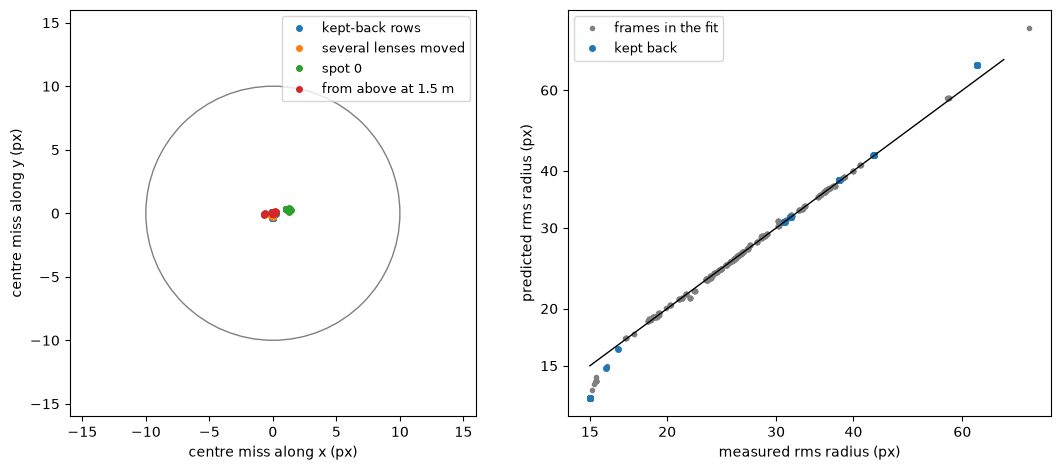

In [17]:
fig, (ax_centre, ax_size) = plt.subplots(1, 2, figsize=(11, 4.8))
for name, frames_in in (
    ("kept-back rows", rows),
    ("several lenses moved", combined),
    ("spot 0", spot_0),
    ("from above at 1.5 m", above_kept),
):
    miss = (centre_model - centre_px)[frames_in]
    ax_centre.plot(miss[:, 0], miss[:, 1], "o", markersize=4, label=name)
ax_centre.add_patch(plt.Circle((0, 0), 10, fill=False, color="grey"))
ax_centre.set(
    xlim=(-16, 16),
    ylim=(-16, 16),
    aspect="equal",
    xlabel="centre miss along x (px)",
    ylabel="centre miss along y (px)",
)
ax_centre.legend(loc="upper right", fontsize=9)
ax_size.loglog(
    rms_px[has_size & used],
    radius_model[has_size & used],
    ".",
    color="grey",
    label="frames in the fit",
)
ax_size.loglog(
    rms_px[has_size & kept_back],
    radius_model[has_size & kept_back],
    "o",
    markersize=4,
    label="kept back",
)
ax_size.plot([15, 70], [15, 70], color="black", linewidth=1)
ticks = [15, 20, 30, 40, 60]
ax_size.set(
    xlabel="measured rms radius (px)",
    ylabel="predicted rms radius (px)",
    xticks=ticks,
    xticklabels=ticks,
    yticks=ticks,
    yticklabels=ticks,
)
ax_size.minorticks_off()
ax_size.legend(loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig(HERE / "figures/neoarm_fit_misses.png", dpi=110)

## The fitted model

The fitted numbers go to `neoarm_fit.json`, with the camera's mirror choice, the corrector's state
and the objective. The simulated NEOARM does not read this file.

In [18]:
(HERE / "neoarm_fit.json").write_text(
    json.dumps(
        dict(
            source="neoarm_fit.ipynb: the column of notebook 1 fitted to "
            "recordings/lens_changes_simulated_corrector_off_2026-11-22.csv",
            units="z and lengths in L; centres in um; kick in 1e-7 rad per DAC unit; "
            "offset in 1e-4 rad; camera_shift in px; "
            "spread in metres per L; gap, bore and spread as natural logarithms",
            misfit=float(cost[BEST]),
            mirror=MIRROR,
            corrector_on=CORRECTOR_ON,
            objective_f=float(np.exp(FIXED["objective_f"])),
            aligned_deflectors=aligned,
            numbers={name: np.asarray(value).tolist() for name, value in fitted.items()},
        ),
        indent=1,
    )
)
print("wrote neoarm_fit.json")

wrote neoarm_fit.json


## The deflector response for the correction routine

The correction routine `centre_beam.py` moves the beam back to the middle of the SightX with
CLA1 in MAG and the projector deflector PLA in DIFF (scenario S3, example E4). It needs, for
the row the microscope is
at, how far a change of the deflector moves the beam. The fitted model gives that as a 2 x 2
matrix in pixels per DAC unit, from its derivatives, at the lens values that the recording read
at each MAG and DIFF row. The console tables are not used here: they give CM as 58624, where the
microscope reads 26624. The matrices go to `neoarm_response.json`, so that the routine needs no
TemGym and no JAX at the microscope.

In [19]:
response_rows = {"MAG": range(6, 25), "DIFF": range(0, 15)}
centring_deflector = {"MAG": "CLA1", "DIFF": "PLA"}


def deflector_response(lens_row, deflector):
    """Return the fitted model's px per DAC unit of ``deflector`` for one row of ``lenses``.

    The matrix is [[dx/dx, dx/dy], [dy/dx, dy/dy]]. The response is the same at every deflector
    value, so the aligned state serves.
    """

    def centre(deflector_dac):
        return beam_on_sightx(fitted, FIXED, CORRECTOR_ON, lens_row, deflector_dac, MIRROR)[0]

    per_deflector = jax.jacfwd(centre)(jnp.zeros((len(DEFLECTORS), 2)))
    return np.asarray(per_deflector[:, DEFLECTORS.index(deflector), :])


response = {}
for mode, selectors in response_rows.items():
    response[mode] = {}
    for selector in selectors:
        # Every frame of the row's plain setting has the row's lens values.
        first = int(np.flatnonzero(setting == f"{mode} row {selector}")[0])
        matrix = deflector_response(jnp.asarray(lenses[first]), centring_deflector[mode])
        response[mode][str(selector)] = dict(
            label=console["rows"][mode][selector]["mag"][2],
            deflector=centring_deflector[mode],
            px_per_dac=np.round(matrix, 5).tolist(),
        )
(HERE / "neoarm_response.json").write_text(
    json.dumps(
        dict(
            source="neoarm_fit.ipynb: the fitted model's deflector response at each recorded row",
            **response,
        ),
        indent=1,
    )
)
for mode in response_rows:
    for selector, entry in list(response[mode].items())[:: len(response[mode]) // 3]:
        print(
            f"{mode} row {selector} ({entry['label']}): {entry['deflector']} {entry['px_per_dac']}"
        )
print("wrote neoarm_response.json")

MAG row 6 (X8000): CLA1 [[-0.01808, -0.01663], [-0.01612, 0.01937]]
MAG row 12 (X30k): CLA1 [[-0.07998, -0.07911], [-0.07655, 0.08579]]
MAG row 18 (X120k): CLA1 [[-0.49458, -0.4669], [-0.45217, 0.53008]]
MAG row 24 (X500k): CLA1 [[-2.05569, -1.86317], [-1.8059, 2.20182]]
DIFF row 0 (8cm): PLA [[0.00743, 0.01341], [0.01426, -0.00728]]
DIFF row 5 (25cm): PLA [[0.00743, 0.01341], [0.01426, -0.00728]]
DIFF row 10 (80cm): PLA [[0.00743, 0.01341], [0.01426, -0.00728]]
wrote neoarm_response.json


## The illumination at the specimen, with the rulers (example E23)

The fitted model predicts what the SightX shows, in pixels. Its lengths at the specimen are in
its own unit, which the recording does not fix. Two rulers turn pixels into nm and mrad:
`record_rulers.py` records a cross grating at MAG row 13 (a 463 nm period) and a gold film at
DIFF row 10 (the 111 ring at the wavelength over d(111)). The model carries each ruler to other
settings by its own ratios, which do not depend on the held numbers (a check of 2026-11-22: under
1 % for the patch and the DIFF disc).

The cell below reads the newest ruler frames. For a ruler that is missing it says so, and the
sizes or the angles stay without a scale.

In [20]:
RULER_FOLDER = HERE / "output/record_rulers"
rulers = {}
for name in ("grating", "gold"):
    found = sorted(RULER_FOLDER.glob(f"*/ruler_{name}.npz"))
    if found:
        rulers[name] = np.load(found[-1])
        print(f"{name}: {found[-1].parent.name}, {float(rulers[name]['measured_px']):.2f} px")
if "grating" in rulers:
    nm_per_px = 463.0 / float(rulers["grating"]["measured_px"])
    print(f"MAG row 13: {nm_per_px:.3f} nm per px")
else:
    print("no grating ruler: run record_rulers.py with RULER = 'grating'")
if "gold" in rulers:
    wavelength_m = float(energy2wavelength(VOLTAGE))
    mrad_per_px = wavelength_m / AU_RINGS["111"] * 1e3 / float(rulers["gold"]["measured_px"])
    print(f"DIFF row 10: {mrad_per_px:.4f} mrad per px")
else:
    print("no gold ruler: the angles below stay in the model's own units, not mrad")

grating: 2026-11-22_225449, 58.36 px
gold: 2026-11-23_115709, 46.00 px
MAG row 13: 7.933 nm per px
DIFF row 10: 0.2315 mrad per px


For a setting, the model traces the source's centre and its rms spread of angles to the plane
that the projector images onto the SightX at MAG row 13. The beam's rms size there, times that
row's magnification, is the patch the SightX shows. Its rms angle, times the camera's response
to an angle at DIFF row 10, is the disc the SightX shows in DIFF. The rulers turn both into nm
and mrad. The settings are MAG row 13 with CL3 at its value and 3000 and 6000 units above it.

In [21]:
def camera_response(label):
    """Return how a ray at the plane z = 0 lands on the SightX in the setting ``label``.

    The result is A (px per unit of position) and B (px per rad), each 2 x 2.
    """
    lens_dac, deflector_dac = (
        jnp.asarray(x[np.flatnonzero(setting == label)[0]]) for x in (lenses, deflectors)
    )
    below = column(fitted, FIXED, CORRECTOR_ON, lens_dac, deflector_dac)[FIRST_AFTER_SPECIMEN:]

    def on_sightx(v):
        ray = Ray(x=v[0], y=v[1], dx=v[2], dy=v[3], z=0.0, pathlength=0.0, voltage=VOLTAGE)
        out = run_to_end(ray, below)
        return jnp.stack([out.x, MIRROR * out.y]) / PIXEL_M

    response = jax.jacfwd(on_sightx)(jnp.zeros(4))
    return response[:, :2], response[:, 2:]


if "grating" in rulers:
    mag_a, mag_b = camera_response("MAG row 13")
    # The plane the projector images onto the SightX: a ray through it at height 0 lands at one
    # place whatever its angle, so B = h A there.
    image_plane = float(jnp.sum(mag_a * mag_b) / jnp.sum(mag_a * mag_a))
    px_per_length = float(jnp.sqrt(jnp.abs(jnp.linalg.det(mag_a))))
    diff_a, diff_b = camera_response("DIFF row 10")
    px_per_rad = float(jnp.sqrt(jnp.abs(jnp.linalg.det(diff_b - image_plane * diff_a))))
    row_13 = int(np.flatnonzero(setting == "MAG row 13")[0])
    spread = jnp.exp(fitted["spread"])
    for cl3_step in (0, 3000, 6000):
        lens_dac = jnp.asarray(lenses[row_13]).at[1].add(cl3_step)
        parts = column(fitted, FIXED, CORRECTOR_ON, lens_dac, jnp.asarray(deflectors[row_13]))
        rays = Ray(
            x=jnp.zeros(2),
            y=jnp.zeros(2),
            dx=jnp.array([0.0, spread]),
            dy=jnp.zeros(2),
            z=jnp.full(2, z_drawing["Source"]),
            pathlength=jnp.zeros(2),
            voltage=jnp.full(2, VOLTAGE),
        )
        at = run_to_end(rays, parts[:FIRST_AFTER_SPECIMEN] + [Plane(z=image_plane)])
        size_nm = float(abs(at.x[1] - at.x[0])) * px_per_length * nm_per_px
        angle_px = float(abs(at.dx[1] - at.dx[0])) * px_per_rad
        if "gold" in rulers:
            angle = f"{angle_px * mrad_per_px:.2f} mrad"
        else:
            angle = f"{angle_px:.1f} px of DIFF row 10"
        print(f"MAG row 13, CL3 +{cl3_step}: rms size {size_nm:.0f} nm, rms angle {angle}")

MAG row 13, CL3 +0: rms size 1 nm, rms angle 6.81 mrad
MAG row 13, CL3 +3000: rms size 26 nm, rms angle 13.42 mrad
MAG row 13, CL3 +6000: rms size 57 nm, rms angle 20.97 mrad
